![st_thomas](st_thomas.jpg)
# <b>SEIS 631 Final Project - Zillow Home Value Analysis</b>
Jake Holley, Miranda Dahl, Vansh Verma

# <b>Dependency Installs</b>

In [1]:
#%pip install pandas

In [2]:
#%pip install matplotlib

In [3]:
#%pip install xgboost

In [4]:
#%pip install pyarrow

In [5]:
#%pip install scikit-learn

In [6]:
#%pip install seaborn

In [7]:
#%pip install geopandas

# <b>Package Imports</b>

In [8]:
# standard packages
# pyarrow for parquet
# xgboost for gradient boosting
# sklearn for ML utilities

import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.dates as mdates
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

# <b>Global Plotting Format</b>

In [9]:
# setting plotting style globally

plt.rcParams['text.color'] = '#1cdff5'
plt.rcParams['axes.labelcolor'] = '#1cdff5'
plt.rcParams['xtick.color'] = '#1cdff5'
plt.rcParams['ytick.color'] = '#1cdff5'
plt.rcParams['axes.titlecolor'] = '#1cdff5'
plt.rcParams['axes.edgecolor'] = '#1cdff5'
plt.rcParams['figure.facecolor'] = '#404040'
plt.rcParams['axes.facecolor'] = '#404040'

# <b>Formatting and Helper Functions</b>

In [10]:
# these are just used by matplotlib's FunctionFormatter to format values correctly on plots
def number_formatter(x, pos):
    if x >= 10**9:
        return f'{x/10**9:.1f}B'
    elif x >= 10**6:
        return f'{x/10**6:.1f}M'
    elif x >= 10**3:
        return f'{x/10**3:.1f}K'
    else:
        return f'{x:.0f}'

def currency_formatter(x, pos):
    if x >= 10**9:
        return f'${x/10**9:.1f}B'
    elif x >= 10**6:
        return f'${x/10**6:.1f}M'
    elif x >= 10**3:
        return f'${x/10**3:.1f}K'
    else:
        return f'${x:.0f}'

def percent_formatter(x, pos):
    return f'{x*100:.1f}%'

# define shared cleaning function for time-series datasets
def clean_forward_fill(df, label):
    print(f"\n{label} original shape:", df.shape)
    date_cols = [col for col in df.columns if col.startswith("20")]
    df[date_cols] = df[date_cols].ffill(axis=1)
    df = df[~df[date_cols[-6:]].isnull().any(axis=1)]
    print(f"{label} cleaned shape:", df.shape)
    return df

# drop nulls
def clean_dropna(df, label):
    print(f"\n{label} original shape:", df.shape)
    df = df.dropna()
    print(f"{label} cleaned shape:", df.shape)
    return df

# <b>Data Loading/Preparation</b>

In [11]:
# load datasets

zhvi = pd.read_csv("Metro_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv")
zori = pd.read_csv("Metro_zori_uc_sfrcondomfr_sm_month.csv")
inventory = pd.read_csv("Metro_invt_fs_uc_sfrcondo_sm_month.csv")
sales = pd.read_csv("Metro_sales_count_now_uc_sfrcondo_month.csv")
doz = pd.read_csv("Metro_mean_doz_pending_uc_sfrcondo_sm_month.csv")

# apply forward fill cleaning
zhvi = clean_forward_fill(zhvi, "ZHVI")
zori = clean_forward_fill(zori, "ZORI")
doz = clean_forward_fill(doz, "Mean DoZ")

# apply dropna cleaning
inventory = clean_dropna(inventory, "Inventory")
sales = clean_dropna(sales, "Sales Count")

# standard columns to retain
id_cols = ["RegionName", "StateName"]

# identify date columns dynamically
date_cols_zhvi = [col for col in zhvi.columns if col.startswith("20")]
date_cols_zori = [col for col in zori.columns if col.startswith("20")]
date_cols_doz = [col for col in doz.columns if col.startswith("20")]
date_cols_inv = [col for col in inventory.columns if col.startswith("20")]
date_cols_sales = [col for col in sales.columns if col.startswith("20")]

# melt datasets to long format
df_zhvi = zhvi.melt(id_vars=id_cols, value_vars=date_cols_zhvi, var_name="Date", value_name="HomeValue")
df_zori = zori.melt(id_vars=id_cols, value_vars=date_cols_zori, var_name="Date", value_name="RentIndex")
df_doz = doz.melt(id_vars=id_cols, value_vars=date_cols_doz, var_name="Date", value_name="MeanDoZ")
df_inv = inventory.melt(id_vars=id_cols, value_vars=date_cols_inv, var_name="Date", value_name="Inventory")
df_sales = sales.melt(id_vars=id_cols, value_vars=date_cols_sales, var_name="Date", value_name="SalesCount")

# convert dates
for df in [df_zhvi, df_zori, df_doz, df_inv, df_sales]:
    df['Date'] = pd.to_datetime(df['Date'])
    
# merge all datasets
merged = df_zhvi.merge(df_zori, on=["RegionName", "StateName", "Date"], how="inner")
merged = merged.merge(df_doz, on=["RegionName", "StateName", "Date"], how="inner")
merged = merged.merge(df_inv, on=["RegionName", "StateName", "Date"], how="inner")
merged = merged.merge(df_sales, on=["RegionName", "StateName", "Date"], how="inner")

# add year and month columns
merged["Year"] = merged["Date"].dt.year
merged["Month"] = merged["Date"].dt.month


ZHVI original shape: (895, 308)
ZHVI cleaned shape: (895, 308)

ZORI original shape: (649, 128)
ZORI cleaned shape: (537, 128)

Mean DoZ original shape: (740, 90)
Mean DoZ cleaned shape: (577, 90)

Inventory original shape: (928, 90)
Inventory cleaned shape: (863, 90)

Sales Count original shape: (94, 211)
Sales Count cleaned shape: (87, 211)


In [12]:
# prepping inventory listing data

# read in data
month_for_sale_listing_df = pd.read_csv('Metro_invt_fs_uc_sfrcondo_sm_month.csv')

# pivoting
month_for_sale_listing_df = month_for_sale_listing_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'count')

# convert dates
month_for_sale_listing_df['Date'] = pd.to_datetime(month_for_sale_listing_df['Date'])

# group by region
month_for_sale_listing_df = month_for_sale_listing_df.groupby(['RegionName', 'Date'])['count'].mean().reset_index()

# filter to US
month_for_sale_listing_df = month_for_sale_listing_df[month_for_sale_listing_df['RegionName'] == 'United States']


In [13]:
# prepping sales count data

# read in data
sales_count_all_weekly_df = pd.read_csv('Metro_sales_count_raw_uc_sfrcondo_sm_week.csv')

# pivoting
sales_count_all_weekly_df = sales_count_all_weekly_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'count')

# convert dates
sales_count_all_weekly_df['Date'] = pd.to_datetime(sales_count_all_weekly_df['Date'])

# group by region
sales_count_all_weekly_df = sales_count_all_weekly_df.groupby(['RegionName', 'Date'])['count'].mean().reset_index()

# filter to US
sales_count_all_weekly_df = sales_count_all_weekly_df[sales_count_all_weekly_df['RegionName'] == 'United States']

In [14]:
# prepping median sales price data

# read in data
median_sales_price_all_weekly_df = pd.read_csv('Metro_median_sale_price_uc_sfrcondo_sm_week.csv')

# pivoting
median_sales_price_all_weekly_df = median_sales_price_all_weekly_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'price')

# convert dates
median_sales_price_all_weekly_df['Date'] = pd.to_datetime(median_sales_price_all_weekly_df['Date'])

# group by region
median_sales_price_all_weekly_df = median_sales_price_all_weekly_df.groupby(['RegionName', 'Date'])['price'].mean().reset_index()

# filter to US
median_sales_price_all_weekly_df = median_sales_price_all_weekly_df[median_sales_price_all_weekly_df['RegionName'] == 'United States']

In [15]:
# prepping mean sales price data

# read in data
mean_sales_price_all_weekly_df = pd.read_csv('Metro_mean_sale_price_uc_sfrcondo_sm_week.csv')

# pivoting
mean_sales_price_all_weekly_df = mean_sales_price_all_weekly_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'price')

# convert dates
mean_sales_price_all_weekly_df['Date'] = pd.to_datetime(mean_sales_price_all_weekly_df['Date'])

# group by region
mean_sales_price_all_weekly_df = mean_sales_price_all_weekly_df.groupby(['RegionName', 'Date'])['price'].mean().reset_index()

# filter to US
mean_sales_price_all_weekly_df = mean_sales_price_all_weekly_df[mean_sales_price_all_weekly_df['RegionName'] == 'United States']


In [16]:
# prepping homes sold above list

# read in data
pct_sold_above_list_all_weekly_df = pd.read_csv('Metro_pct_sold_above_list_uc_sfrcondo_sm_week.csv')

# pivoting
pct_sold_above_list_all_weekly_df = pct_sold_above_list_all_weekly_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'count')

# convert dates
pct_sold_above_list_all_weekly_df['Date'] = pd.to_datetime(pct_sold_above_list_all_weekly_df['Date'])

# group by region
pct_sold_above_list_all_weekly_df = pct_sold_above_list_all_weekly_df.groupby(['RegionName', 'Date'])['count'].mean().reset_index()

# filter to US
pct_sold_above_list_all_weekly_df = pct_sold_above_list_all_weekly_df[pct_sold_above_list_all_weekly_df['RegionName'] == 'United States']

In [17]:
# prepping homes sold below list

# read in data
pct_sold_below_list_all_weekly_df = pd.read_csv('Metro_pct_sold_below_list_uc_sfrcondo_sm_week.csv')

pct_sold_below_list_all_weekly_df = pct_sold_below_list_all_weekly_df.melt(
    id_vars = ['RegionID','SizeRank','RegionName', 'RegionType', 'StateName'],
    var_name = 'Date',
    value_name = 'count')

# convert dates
pct_sold_below_list_all_weekly_df['Date'] = pd.to_datetime(pct_sold_below_list_all_weekly_df['Date'])

# group by region
pct_sold_below_list_all_weekly_df = pct_sold_below_list_all_weekly_df.groupby(['RegionName', 'Date'])['count'].mean().reset_index()

# filter to US
pct_sold_below_list_all_weekly_df = pct_sold_below_list_all_weekly_df[pct_sold_below_list_all_weekly_df['RegionName'] == 'United States']

In [18]:
# prepping market heat index data

# read in data
market_heatmap_df = pd.read_csv('Metro_market_temp_index_uc_sfrcondo_month.csv')

# filter out nulls
market_heatmap_df = market_heatmap_df.dropna(subset=['StateName'])

# pivoting
market_heatmap_df = market_heatmap_df.melt(
    id_vars=['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName'],
    var_name='Date',
    value_name='Score'
)

# convert dates
market_heatmap_df['Date'] = pd.to_datetime(market_heatmap_df['Date'])

# filter out null scores
market_heatmap_df = market_heatmap_df.dropna(subset=['Score'])

# group
market_heatmap_df = market_heatmap_df.groupby(['StateName', 'Date'])['Score'].mean().reset_index()

# pivoting
market_heatmap_df = market_heatmap_df.pivot(index='StateName', columns='Date', values='Score')

# 1 yr of data
market_heatmap_df = market_heatmap_df.iloc[:, -12:]

# convert dates for seaborn
market_heatmap_df.columns = market_heatmap_df.columns.to_series().dt.strftime('%Y-%m')

In [19]:
# prepping neighborhood data

# read in data
df_nbr = pd.read_csv('neighborhood_values.csv')
file_name = 'neighborhood_values.parquet'

# pivoting
group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'City', 'Metro', 'CountyName']

df_nbr = pd.melt(
    df_nbr,
    id_vars=group_cols,
    var_name='date',
    value_name='nbr_value'
)

# renaming for join
df_nbr['city_state'] = df_nbr['City'] + ', ' + df_nbr['State']

# write to parquet for faster later
df_nbr.to_parquet(file_name, engine='pyarrow', index=False)

In [20]:
# prepping zip data
# was on the fence about figuring out a way to bring this in. on one hand: more data. on the other hand: overfitting.
# in the end, decided the model got accurate enough without it and this way i didn't need to worry about the lack of a 1:1 mapping between zip and neighborhood

# read in data
#df_zip = pd.read_csv('zip_values.csv')
#file_name = 'zip_values.parquet'

# pivoting
#group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'City', 'Metro', 'CountyName']

#df_zip = pd.melt(
#    df_zip,
#    id_vars=group_cols,
#    var_name='date',
#    value_name='zip_value'
#)

# write to parquet for faster later
#df_zip.to_parquet(file_name, engine='pyarrow', index=False)

# preview
#df_zip.head()

In [21]:
# prepping city data

# read in data
df_city = pd.read_csv('city_values.csv')
file_name = 'city_values.parquet'

# pivoting
group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'Metro', 'CountyName']

df_city = pd.melt(
    df_city,
    id_vars=group_cols,
    var_name='date',
    value_name='city_value'
)

# renaming for join
df_city = df_city.rename(columns={'RegionName': 'City'})

# write to parquet for faster later
df_city.to_parquet(file_name, engine='pyarrow', index=False)

In [22]:
# prepping county data

# read in data
df_county = pd.read_csv('county_values.csv')
file_name = 'county_values.parquet'

# pivoting
group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'Metro', 'StateCodeFIPS', 'MunicipalCodeFIPS']

df_county = pd.melt(
    df_county,
    id_vars=group_cols,
    var_name='date',
    value_name='county_value'
)

# renaming for join
df_county = df_county.rename(columns={'RegionName': 'CountyName'})

# write to parquet for faster later
df_county.to_parquet(file_name, engine='pyarrow', index=False)

In [23]:
# prepping msa data

# read in data
df_msa = pd.read_csv('msa_values.csv')
file_name = 'msa_values.parquet'

# pivoting
group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName']

df_msa = pd.melt(
    df_msa,
    id_vars=group_cols,
    var_name='date',
    value_name='msa_value'
)

# renaming for join
df_msa = df_msa.rename(columns={'RegionName': 'city_state'})

# write to parquet for faster later
df_msa.to_parquet(file_name, engine='pyarrow', index=False)

In [24]:
# prepping state data

# read in data
df_state = pd.read_csv('state_values.csv')
file_name = 'state_values.parquet'

# pivoting
group_cols = ['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName']

df_state = pd.melt(
    df_state,
    id_vars=group_cols,
    var_name='date',
    value_name='state_value'
)

# state mapping
state_name_to_code = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA',
    'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH',
    'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY', 'North Carolina': 'NC',
    'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
    'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD', 'Tennessee': 'TN',
    'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA',
    'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY', 'District of Columbia': 'DC'
}

# mapping state name
df_state['State'] = df_state['RegionName'].map(state_name_to_code)


# write to parquet for faster later
df_state.to_parquet(file_name, engine='pyarrow', index=False)

# <b>Vansh</b> - Question 1: 
### Which US real-estate markets are doing best?

In [25]:
# load and preprocess data
q1_df = merged
q1_df['Year'] = q1_df['Date'].dt.year

# aggregate yearly averages for each metric
agg = q1_df.groupby(['RegionName', 'Year'])[
    ['HomeValue', 'RentIndex', 'SalesCount', 'Inventory']
].mean().reset_index()

# compute YoY home value growth
agg['YoY_HomeValue'] = agg.sort_values('Year').groupby('RegionName')['HomeValue'].pct_change()
avg_growth = agg.groupby('RegionName')['YoY_HomeValue'].mean().dropna().reset_index()
avg_growth.columns = ['RegionName', 'Avg_YoY_HomeValue']

# identify top & bottom 10 cities by average YoY growth
top10 = avg_growth.sort_values('Avg_YoY_HomeValue', ascending=False).head(10)['RegionName'].tolist()
bottom10 = avg_growth.sort_values('Avg_YoY_HomeValue', ascending=True).head(10)['RegionName'].tolist()

# filter the data for these cities
trend_df = agg[agg['RegionName'].isin(top10 + bottom10)]

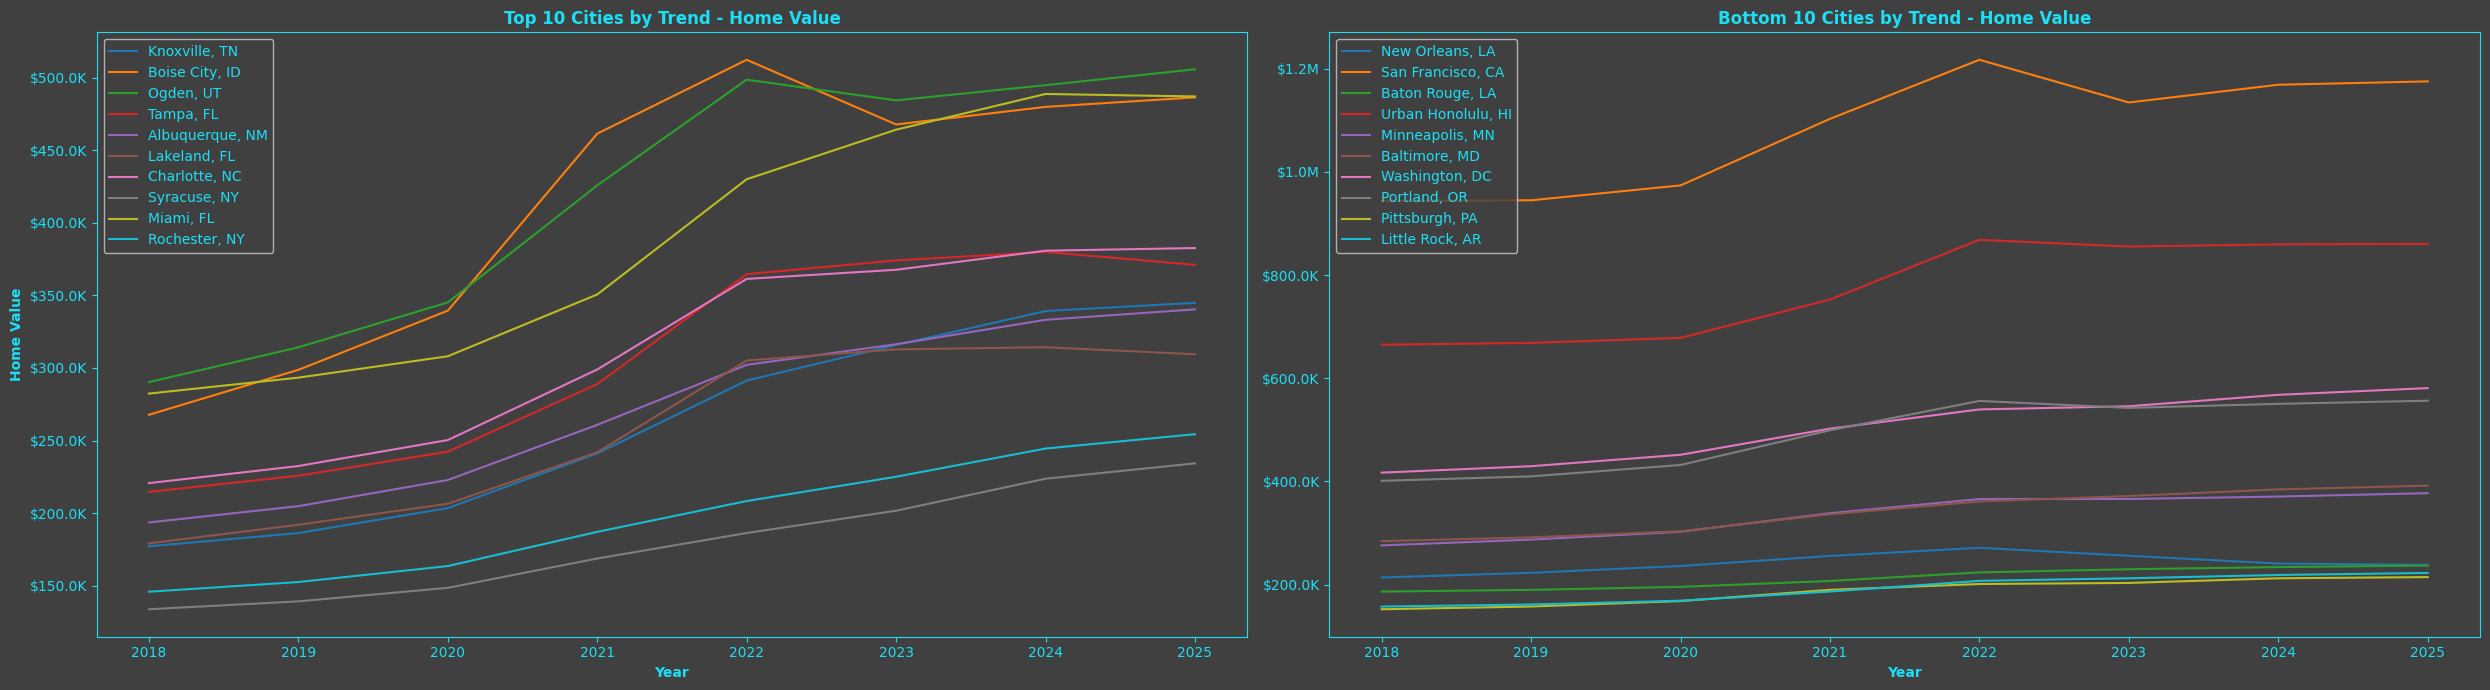

In [26]:
# home value plots
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(25, 7))
column = 'HomeValue'

# top 10 trend cities
for city in top10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax1.plot(city_data['Year'], city_data[column], label=city)

ax1.set_title("Top 10 Cities by Trend - Home Value", fontweight='bold')
ax1.set_xlabel("Year", fontweight='bold')
ax1.set_ylabel("Home Value", fontweight='bold')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
ax1.legend()

# bottom 10 trend cities
for city in bottom10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax2.plot(city_data['Year'], city_data[column], label=city)
    
ax2.set_title("Bottom 10 Cities by Trend - Home Value", fontweight='bold')
ax2.set_xlabel("Year", fontweight='bold')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
ax2.legend()

plt.tight_layout()
plt.show()

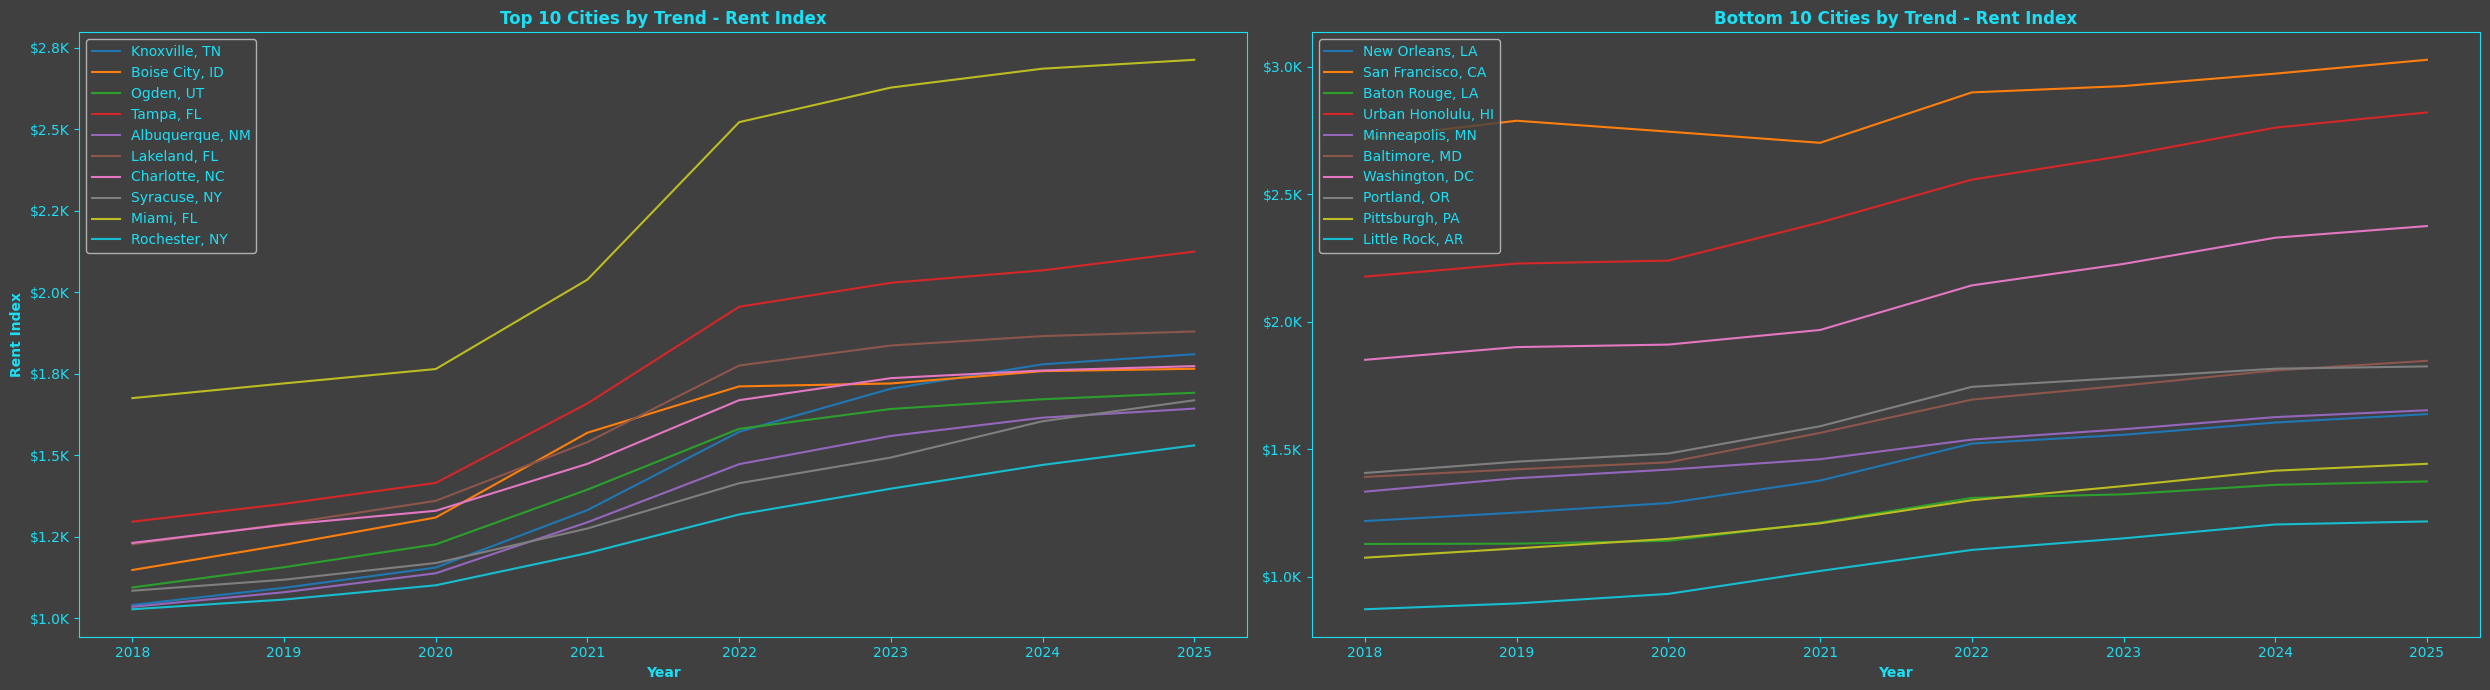

In [27]:
# rent index plots
fig2, (ax3, ax4) = plt.subplots(1, 2, figsize=(25, 7))
column = 'RentIndex'

# top 10 trend cities
for city in top10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax3.plot(city_data['Year'], city_data[column], label=city)

ax3.set_title("Top 10 Cities by Trend - Rent Index", fontweight='bold')
ax3.set_xlabel("Year", fontweight='bold')
ax3.set_ylabel("Rent Index", fontweight='bold')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
ax3.legend()

# bottom 10 trend cities
for city in bottom10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax4.plot(city_data['Year'], city_data[column], label=city)
    
ax4.set_title("Bottom 10 Cities by Trend - Rent Index", fontweight='bold')
ax4.set_xlabel("Year", fontweight='bold')
ax4.yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
ax4.legend()

plt.tight_layout()
plt.show()

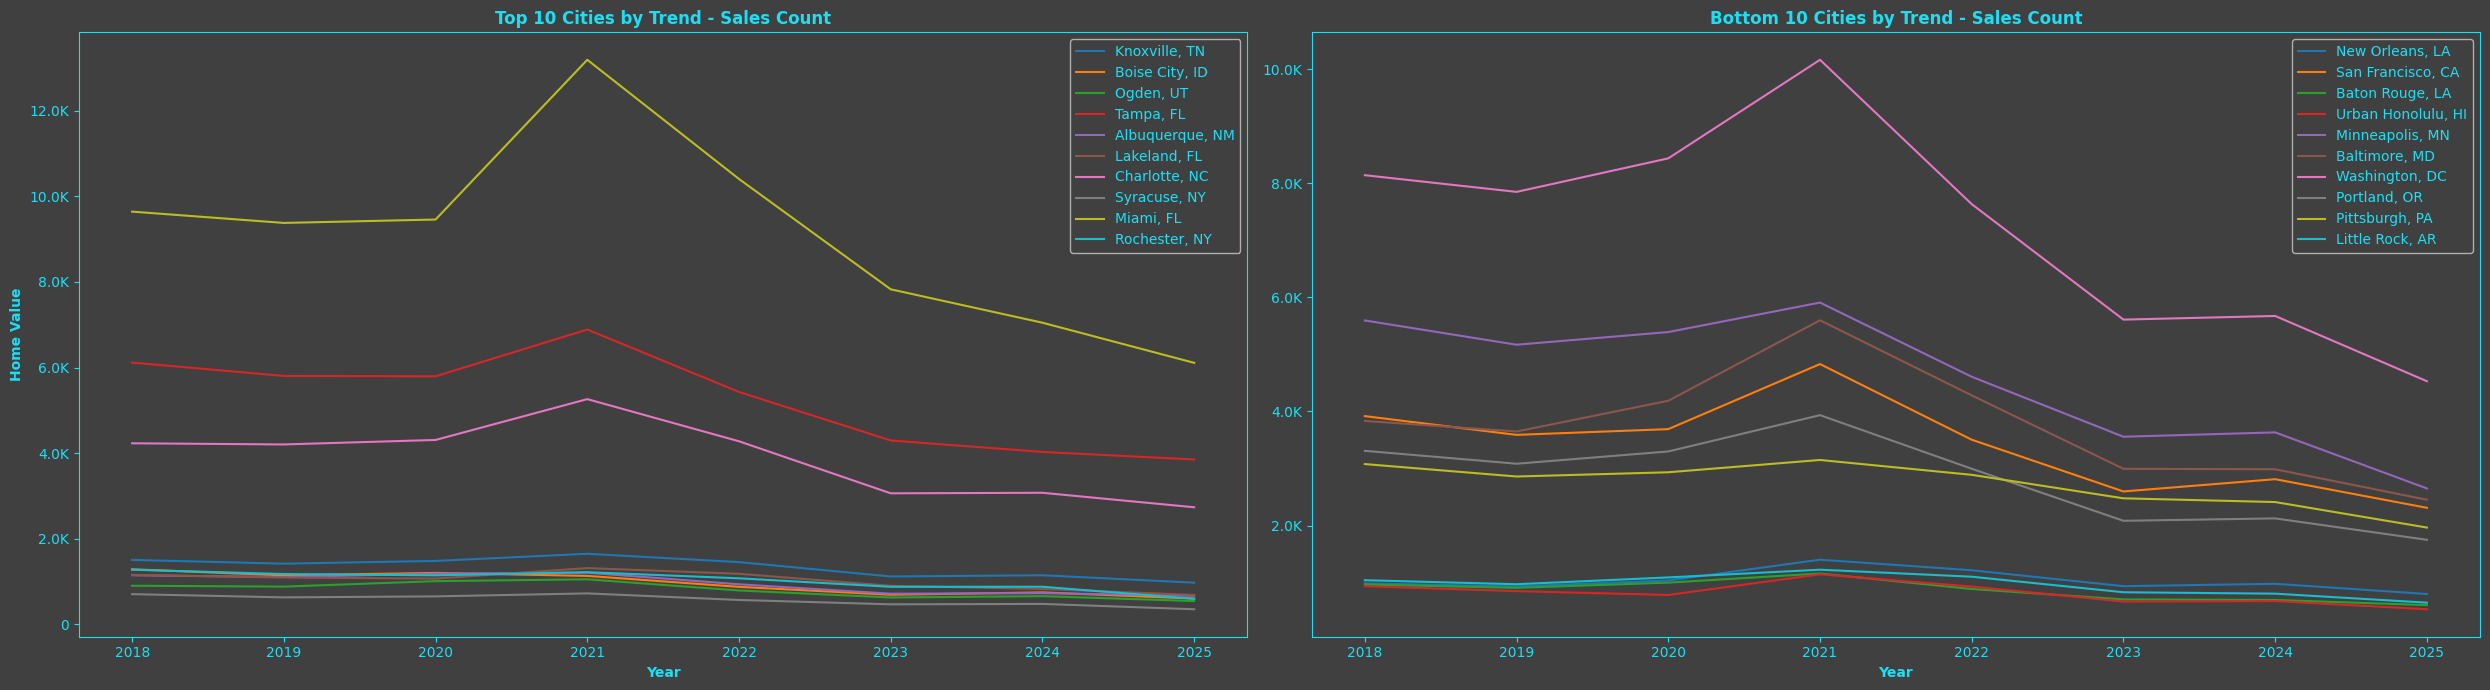

In [28]:
# sales count plots
fig3, (ax5, ax6) = plt.subplots(1, 2, figsize=(25, 7))
column = 'SalesCount'

# top 10 trend cities
for city in top10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax5.plot(city_data['Year'], city_data[column], label=city)

ax5.set_title("Top 10 Cities by Trend - Sales Count", fontweight='bold')
ax5.set_xlabel("Year", fontweight='bold')
ax5.set_ylabel("Home Value", fontweight='bold')
ax5.yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
ax5.legend()

# bottom 10 trend cities
for city in bottom10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax6.plot(city_data['Year'], city_data[column], label=city)
    
ax6.set_title("Bottom 10 Cities by Trend - Sales Count", fontweight='bold')
ax6.set_xlabel("Year", fontweight='bold')
ax6.yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
ax6.legend()

plt.tight_layout()
plt.show()

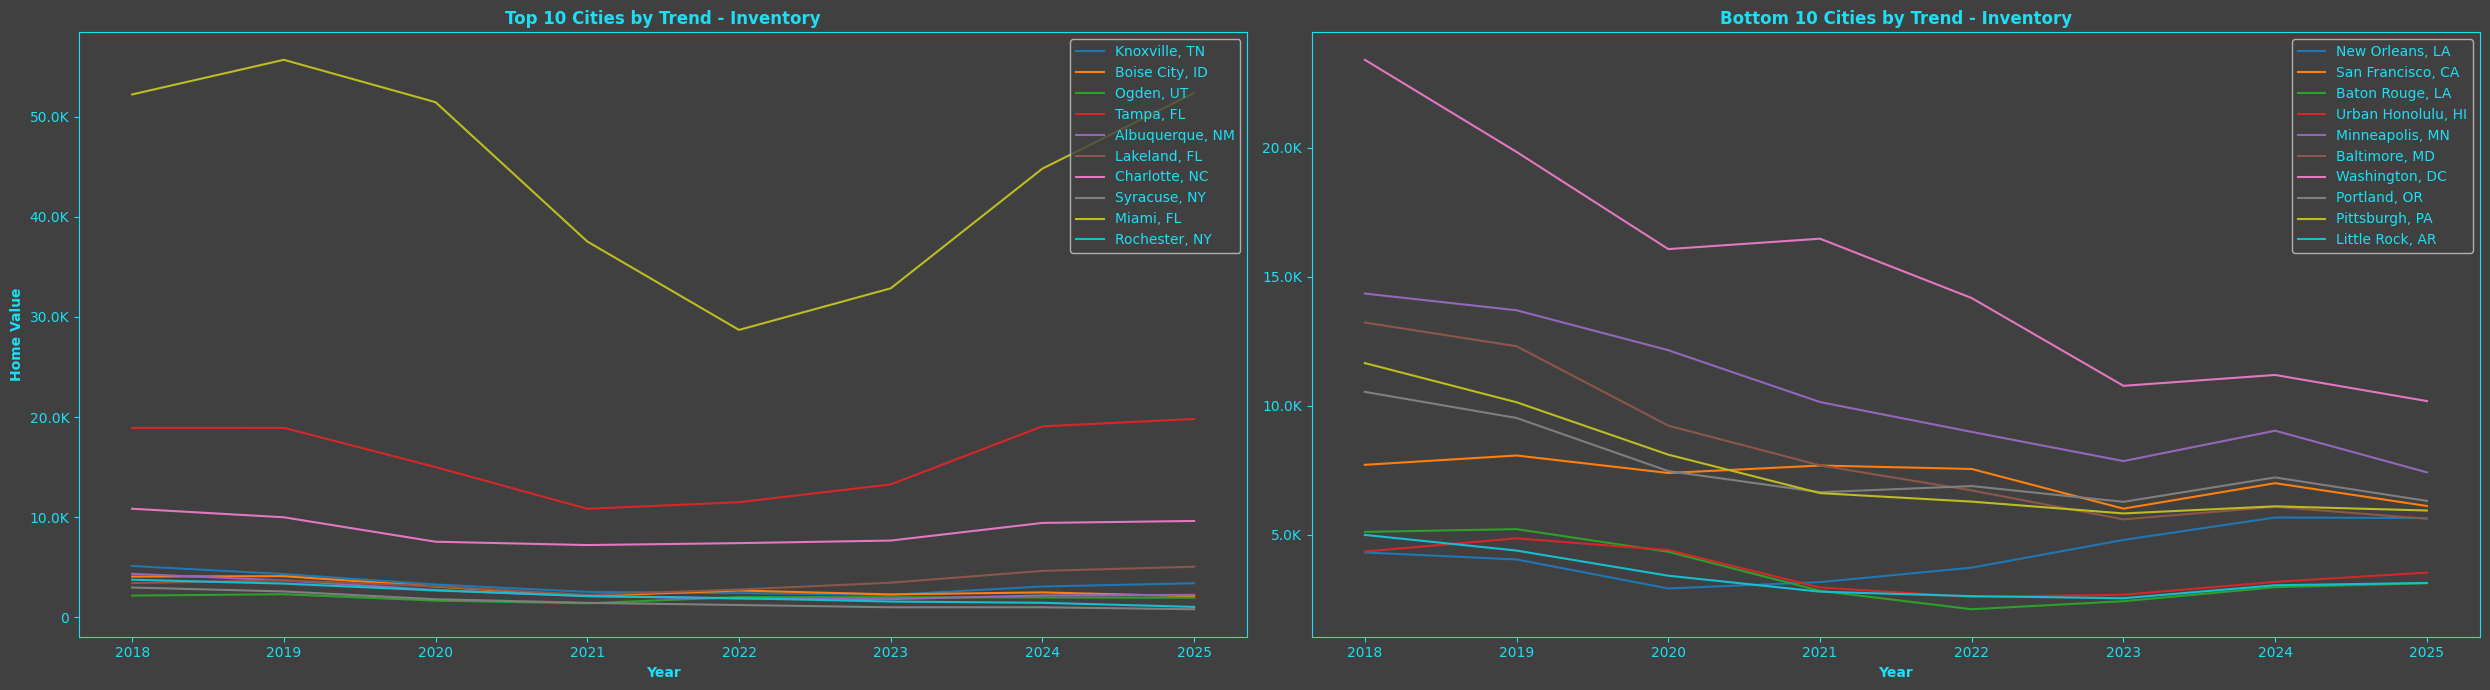

In [29]:
# inventory plots
fig4, (ax7, ax8) = plt.subplots(1, 2, figsize=(25, 7))
column = 'Inventory'

# top 10 trend cities
for city in top10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax7.plot(city_data['Year'], city_data[column], label=city)

ax7.set_title("Top 10 Cities by Trend - Inventory", fontweight='bold')
ax7.set_xlabel("Year", fontweight='bold')
ax7.set_ylabel("Home Value", fontweight='bold')
ax7.yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
ax7.legend()

# bottom 10 trend cities
for city in bottom10:
    city_data = trend_df[trend_df['RegionName'] == city]
    ax8.plot(city_data['Year'], city_data[column], label=city)
    
ax8.set_title("Bottom 10 Cities by Trend - Inventory", fontweight='bold')
ax8.set_xlabel("Year", fontweight='bold')
ax8.yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
ax8.legend()

plt.tight_layout()
plt.show()

### Question 1 Analysis

To identify the strongest real estate markets in the U.S., we conducted a year-over-year trend analysis of key metrics including home value appreciation, rental growth, and inventory levels across all metros. By ranking cities based on their average annual home price growth, we identified the top 10 and bottom 10 performing markets.

The top cities—such as San Jose, CA; Charlotte, NC; and Tampa, FL—demonstrated consistent appreciation in home values and steady increases in rental index, supported by tightening inventory. These markets reflect strong underlying demand and robust investment conditions.

In contrast, the bottom-performing cities exhibited flat or declining home values, weak rental trends, and stagnant inventory, signaling weaker long-term prospects.

Overall, the top 10 metros are ideal candidates for capital deployment due to their sustained growth trajectories, making them highly attractive for both appreciation and income-oriented investment strategies.

# <b>Miranda</b> - Question 2: 
### Are sale prices and inventory listings going up or down overall?

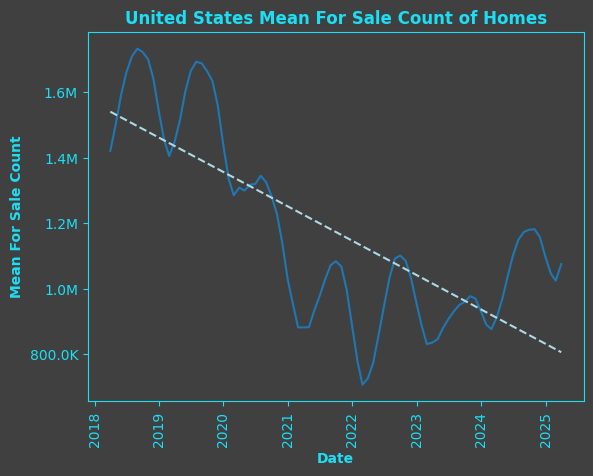

In [30]:
# sales listing plot and linear trend line for sales listings of homes since 2018

# Converting all dates in the table to ordianl values for trend line fitting
x1 = month_for_sale_listing_df['Date'].map(pd.Timestamp.toordinal)
y1 = month_for_sale_listing_df['count']

# add linear trend line
z1 = np.polyfit(x1, y1, 1) 
p1 = np.poly1d(z1)

# sales listing plot
plt.plot(month_for_sale_listing_df['Date'], month_for_sale_listing_df['count'])
plt.plot(month_for_sale_listing_df['Date'], p1(x1), '--', color='lightblue')

# styling and elements
plt.title("United States Mean For Sale Count of Homes", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Mean For Sale Count", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
plt.xticks(rotation=90)
plt.show()

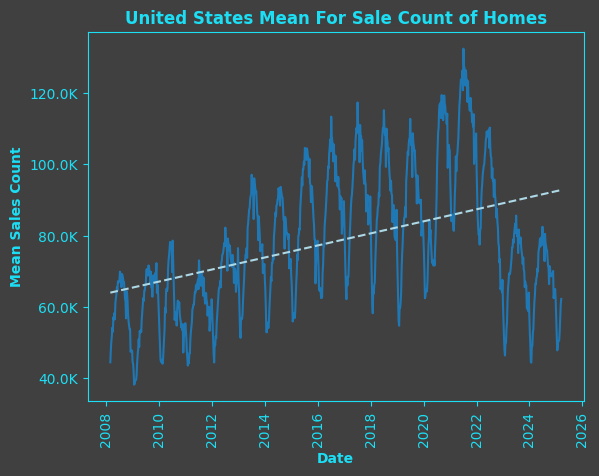

In [31]:
# sales count plot and linear trend line of sales counts of homes since 2018

# converting all dates in the table to ordianl values for trend line fitting
x2 = sales_count_all_weekly_df['Date'].map(pd.Timestamp.toordinal)
y2 = sales_count_all_weekly_df['count']

# add linear trend line
z2 = np.polyfit(x2, y2, 1) 
p2 = np.poly1d(z2)

# sales count plot
plt.plot(sales_count_all_weekly_df['Date'], sales_count_all_weekly_df['count'])
plt.plot(sales_count_all_weekly_df['Date'], p2(x2), '--', color='lightblue')

# styling and elements
plt.title("United States Mean For Sale Count of Homes", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Mean Sales Count", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(number_formatter))
plt.xticks(rotation=90)
plt.show()

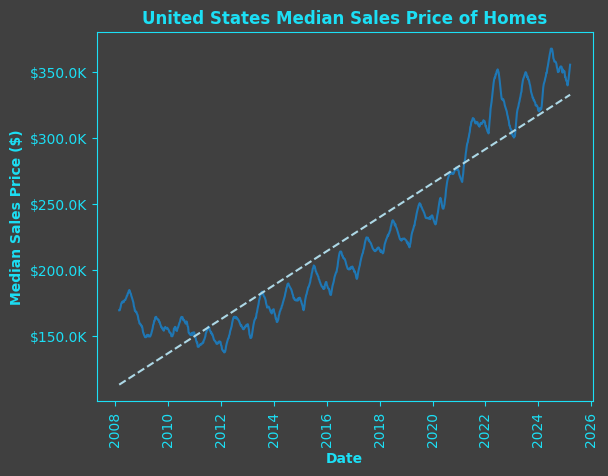

In [32]:
# create linear trend line for median sale price of homes since 2018

# converting all dates in the table to ordianl values for trend line fitting
x3 = median_sales_price_all_weekly_df['Date'].map(pd.Timestamp.toordinal)
y3 = median_sales_price_all_weekly_df['price']

# add linear trend line
z3 = np.polyfit(x3, y3, 1)
p3 = np.poly1d(z3)

# median sales price plot
plt.plot(median_sales_price_all_weekly_df['Date'], median_sales_price_all_weekly_df['price'])
plt.plot(median_sales_price_all_weekly_df['Date'], p3(x3), '--', color='lightblue')

# styling
plt.title("United States Median Sales Price of Homes", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Median Sales Price ($)", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
plt.xticks(rotation=90)
plt.show()

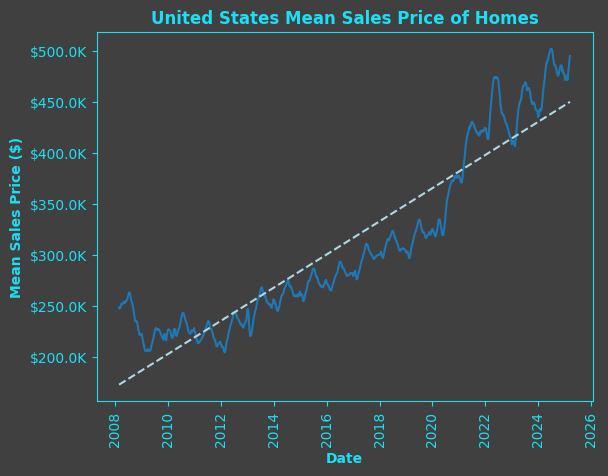

In [33]:
# create linear trend line for mean sale price of homes since 2018

# converting all dates in the table to ordianl values for trend line fitting
x4 = mean_sales_price_all_weekly_df['Date'].map(pd.Timestamp.toordinal)
y4 = mean_sales_price_all_weekly_df['price']

# add linear trend line
z4 = np.polyfit(x4, y4, 1) 
p4 = np.poly1d(z4)

# mean sales price plot
plt.plot(mean_sales_price_all_weekly_df['Date'], mean_sales_price_all_weekly_df['price'])
plt.plot(mean_sales_price_all_weekly_df['Date'], p4(x4), '--', color='lightblue')

# styling and elements
plt.title("United States Mean Sales Price of Homes", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Mean Sales Price ($)", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
plt.xticks(rotation=90)
plt.show()

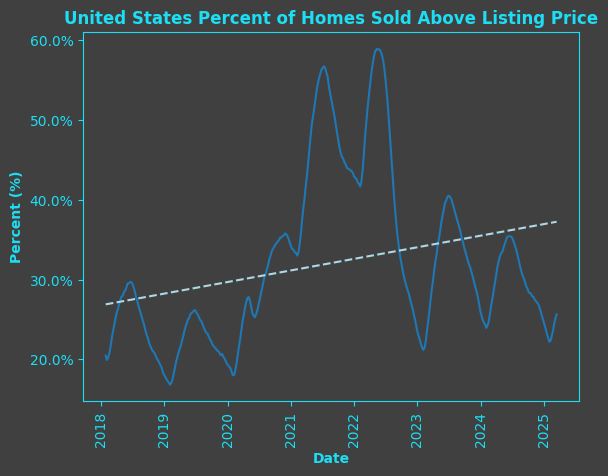

In [34]:
# create linear trend line for percent of homes sold above lising price since 2018

# converting all dates in the table to ordianl values for trend line fitting
x5 = pct_sold_above_list_all_weekly_df['Date'].map(pd.Timestamp.toordinal)
y5 = pct_sold_above_list_all_weekly_df['count']

# add linear trend line
z5 = np.polyfit(x5, y5, 1)
p5 = np.poly1d(z5)

# homes sold above list plot
plt.plot(pct_sold_above_list_all_weekly_df['Date'], pct_sold_above_list_all_weekly_df['count'])
plt.plot(pct_sold_above_list_all_weekly_df['Date'], p5(x5), '--', color='lightblue')

# styling and elements
plt.title("United States Percent of Homes Sold Above Listing Price", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Percent (%)", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(percent_formatter))
plt.xticks(rotation=90)
plt.show()

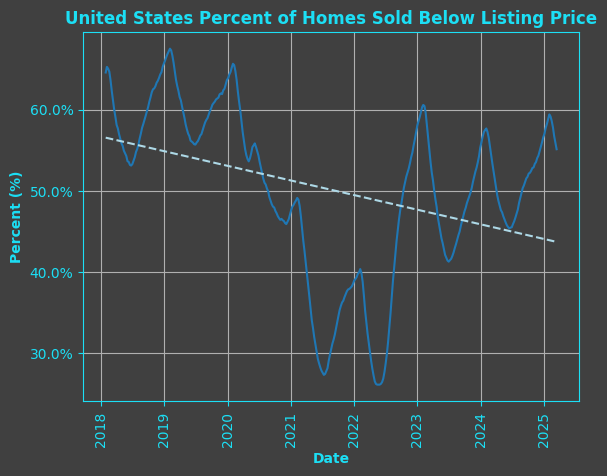

In [35]:
# create linear trend line for percent of homes sold below lising price since 2018

# converting all dates in the table to ordianl values for trend line fitting
x6 = pct_sold_below_list_all_weekly_df['Date'].map(pd.Timestamp.toordinal)
y6 = pct_sold_below_list_all_weekly_df['count']

# add linear trend line
z6 = np.polyfit(x6, y6, 1)
p6 = np.poly1d(z6)

# homes sold below list plot
plt.plot(pct_sold_below_list_all_weekly_df['Date'], pct_sold_below_list_all_weekly_df['count'])
plt.plot(pct_sold_below_list_all_weekly_df['Date'], p6(x6), '--', color='lightblue')

# styling and elements
plt.title("United States Percent of Homes Sold Below Listing Price", fontweight='bold')
plt.xlabel("Date", fontweight='bold')
plt.ylabel("Percent (%)", fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(percent_formatter))
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

### Question 2 Analysis

United States Mean For Sale Count of Homes: The overall trend has been downward since 2018, reaching a low point in 2022 at around 706,905 homes. Since then, the count has started to rise again, reaching 1,075,461 homes as of March 15, 2025.

United States Mean Sales Count of Homes: The average number of homes sold increased steadily from 2018 until a decline began in 2022. The latest count, as of March 15, 2025, is 62,271. The highest recorded value was 132,401 in 2021. There's noticeable seasonality, with sales typically dipping at the start of each year and peaking around mid-year.

United States Home Prices (Median and Mean): Both the median and mean sales prices have shown a steady upward trend over the years. This trend has continued into 2025, with recent prices staying above the long-term trend line. As of March 15, 2025, the median sales price was 355,625 and the mean was $494,819. These have similar signs of seasonality as the mean sales counts of homes. 

States Percent of Homes Sold Above/Below Listing Price: Since 2018, the percentage of homes sold above listing price has gradually increased, while the percentage sold below listing has declined (the relationship is the same but opposite). In recent months, more homes are being sold below listing price, possibly favoring buyers. 

# <b>Miranda</b> - Question 3:
### Should I invest now? Where is the best opportunity?

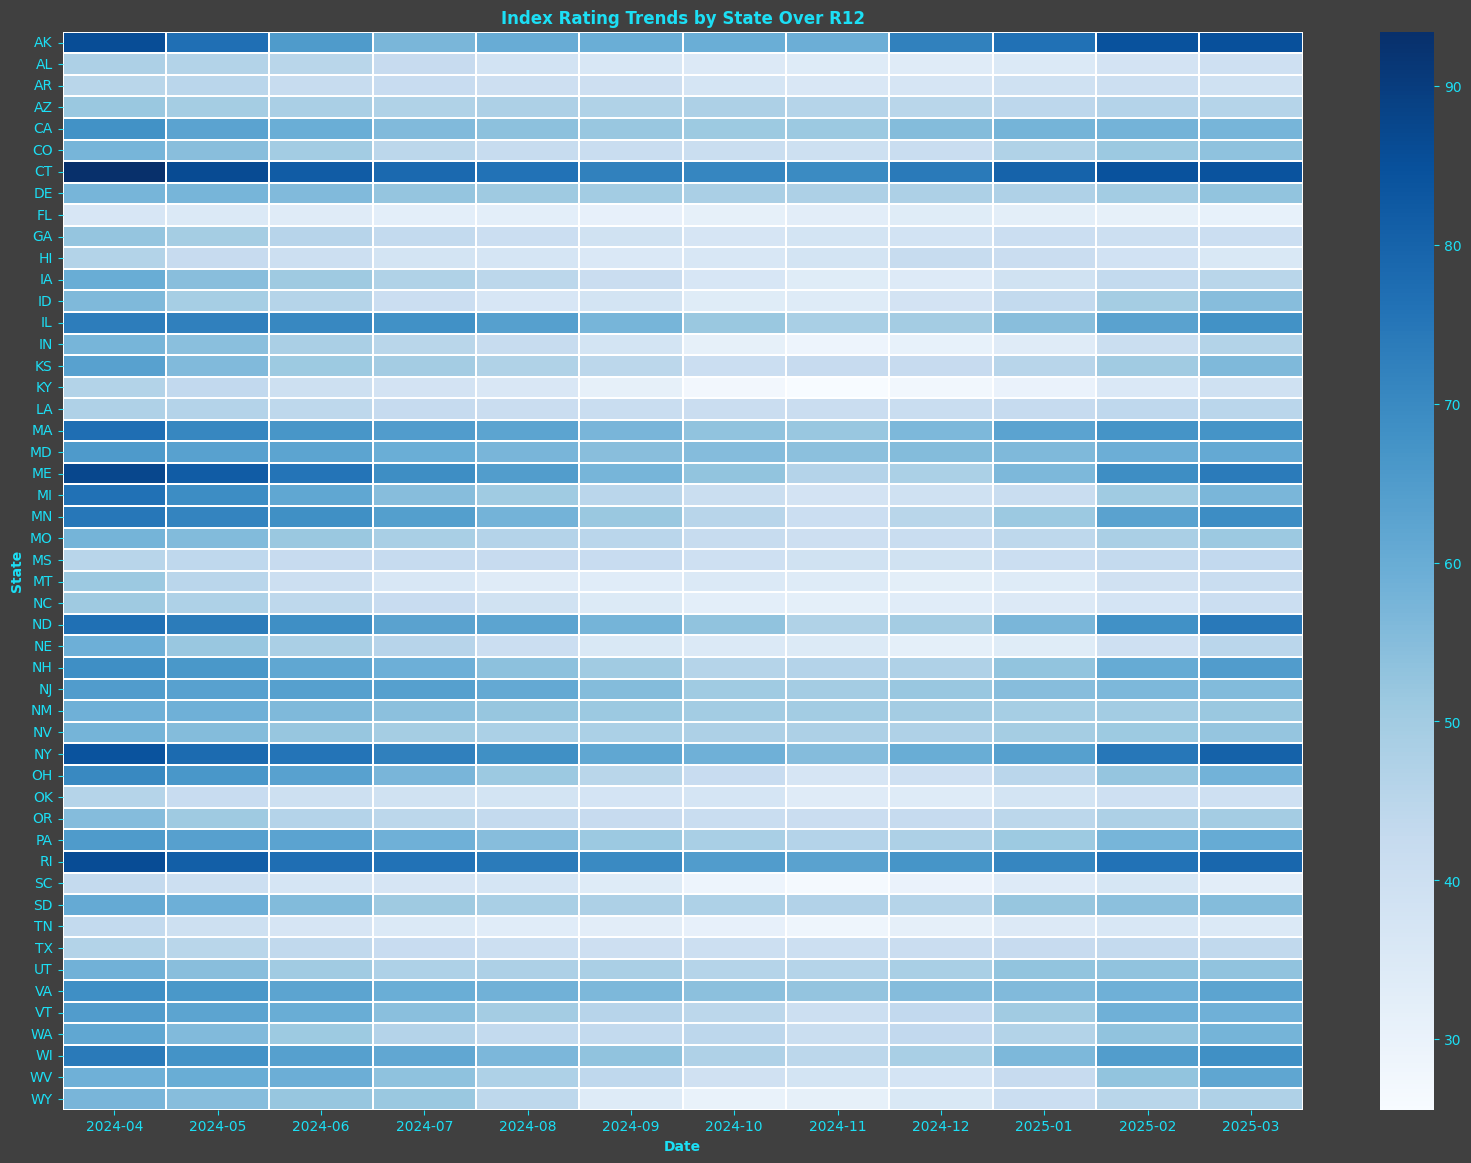

In [36]:
# heat map
#market_heatmap_df.columns = market_heatmap_df.columns.to_series().dt.strftime('%Y-%m')
plt.figure(figsize=(20, 14)) 
sns.heatmap(market_heatmap_df, linewidths=0.1, cmap="Blues")

plt.title('Index Rating Trends by State Over R12', fontweight='bold')
plt.xlabel('Date', fontweight='bold')
plt.ylabel('State', fontweight='bold')
plt.show()

### Question 3 Analysis

This heat map is based on Zillow data for single-family residences and condos, tracking the balance between market supply and demand. It uses engagement and listing performance metrics to determine how favorable the market is for sellers. Darker colors indicate stronger seller markets, while lighter shades indicate the market is more favorable for buyers. Over the past year (R12), the map shows generally lighter colors, showing favor toward a buyer’s market. States like Florida (FL), South Carolina (SC), and Tennessee (TN) have consistently leaned toward buyer friendly conditions over the last 12 months. Based on this visual and supporting data from Question 2, this may be a good time to consider buying.

# <b>Vansh</b> - Question 4:
### How long does real-estate stay on the market before it rents/sells?

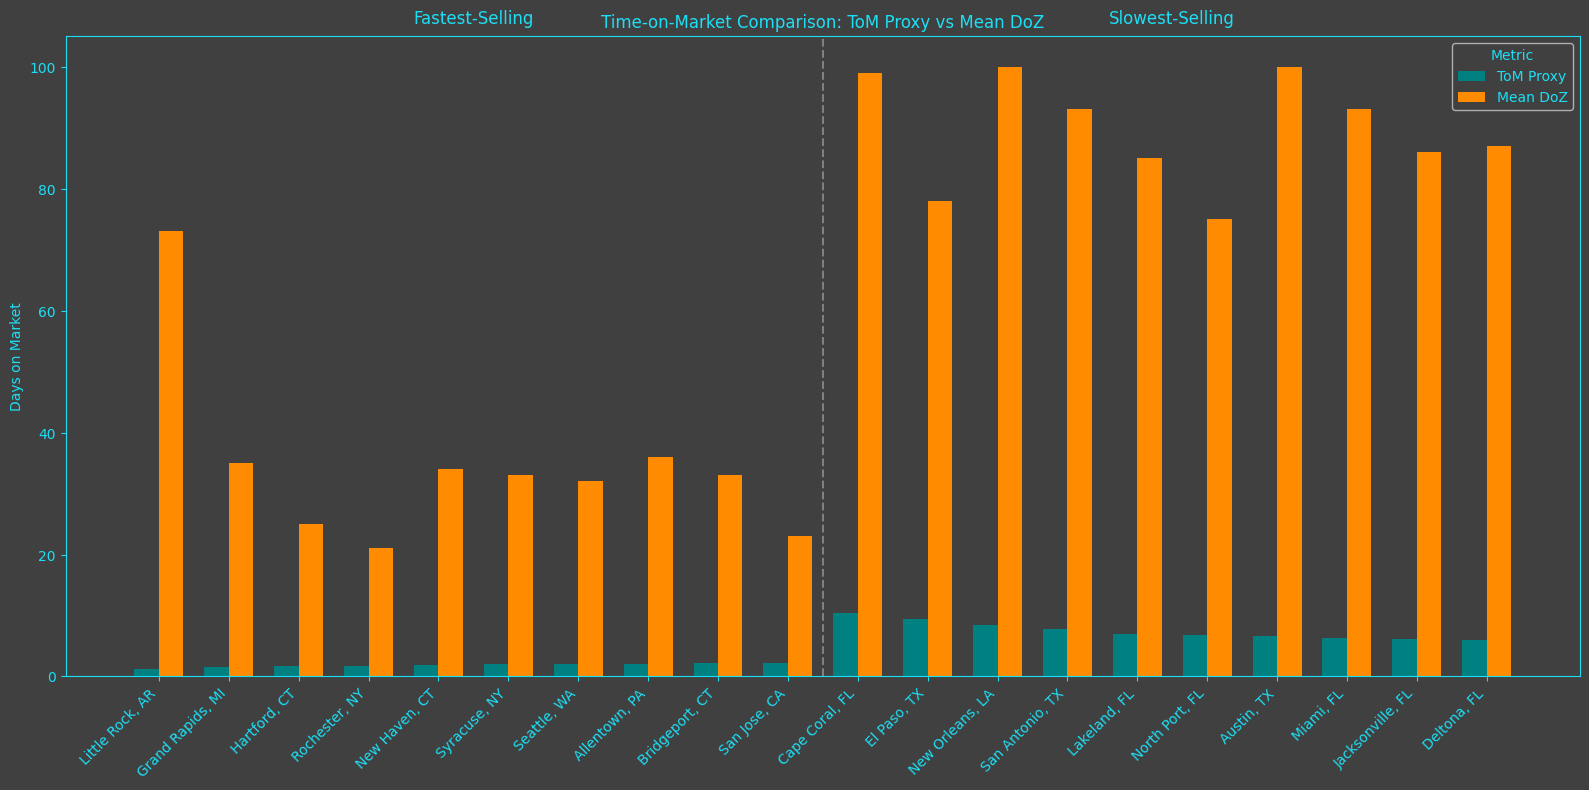

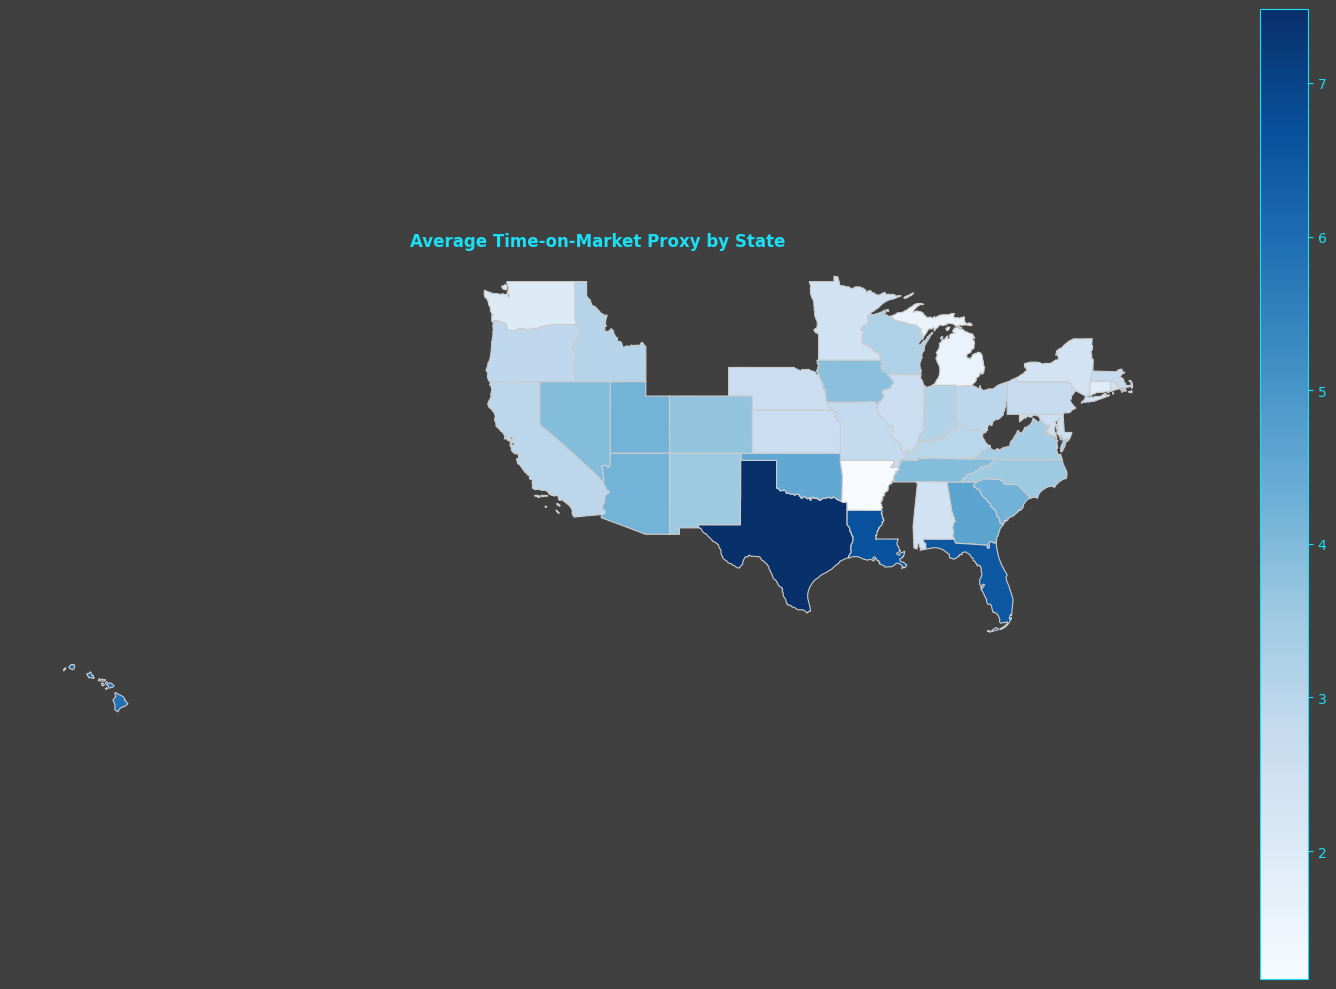

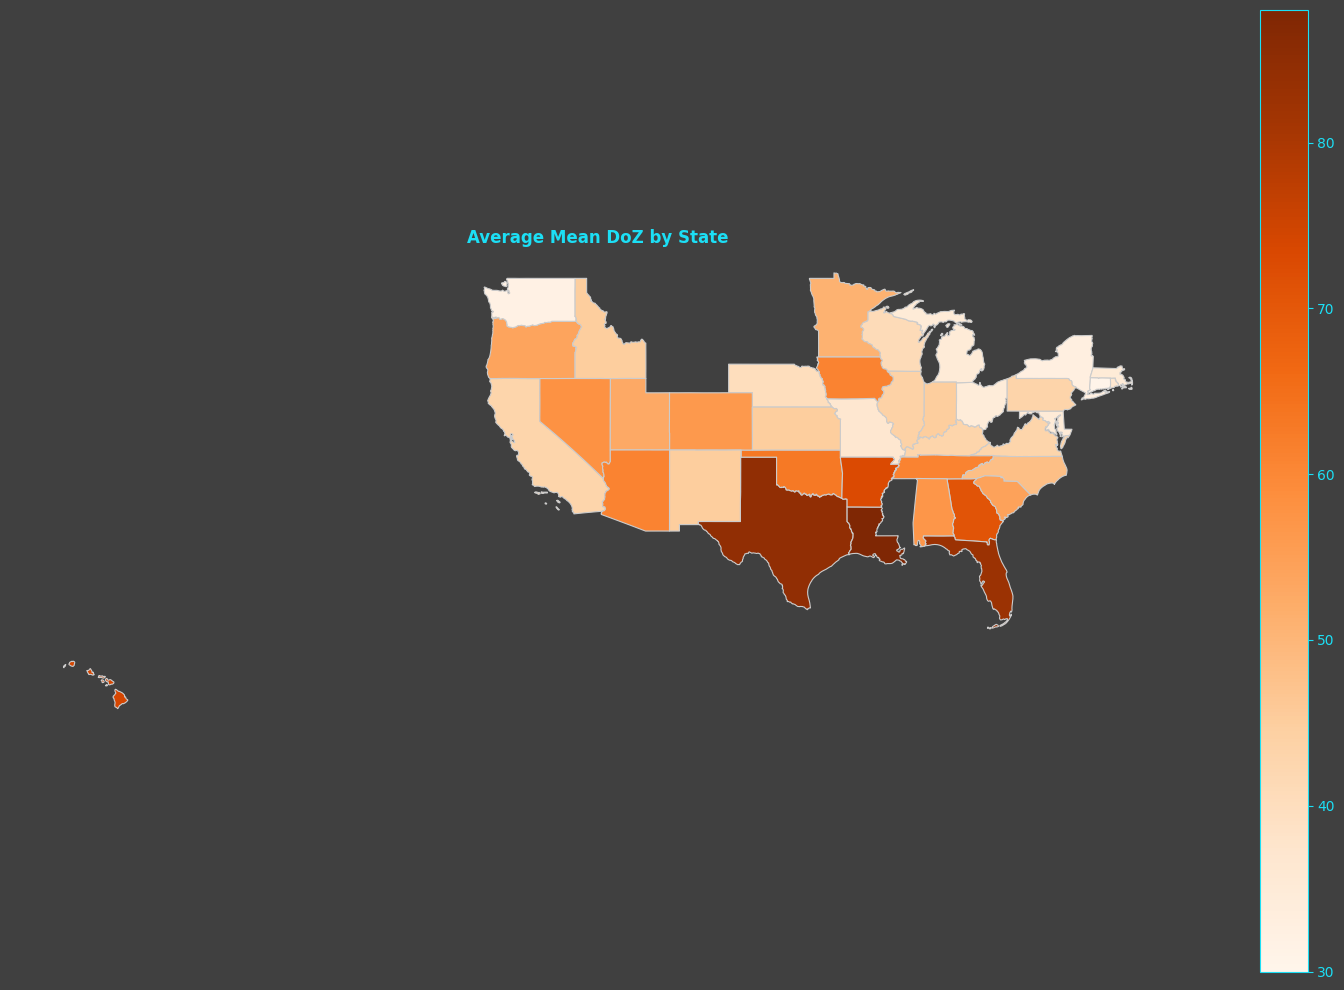

In [37]:
# reload merged dataset
df_q4 = merged

# extract useful columns
df_q4['Month'] = df_q4['Date'].dt.month
df_q4['Year'] = df_q4['Date'].dt.year
df_q4['ToM_proxy'] = df_q4['Inventory'] / (df['SalesCount'] + 1)
df_q4['State'] = df_q4['RegionName'].str.extract(r',\s*(\w{2})$')[0]

# focus on March for consistency across years
df_q4 = df_q4[df_q4['Month'] == 3]
latest_year = df_q4['Year'].max()
prior_year = latest_year - 1

march_latest = df_q4[df_q4['Year'] == latest_year].copy()
march_prior = df_q4[df_q4['Year'] == prior_year].copy()

# create dictionary to map previous year's home values
prior_home_dict = march_prior.set_index('RegionName')['HomeValue'].to_dict()

# compute YoY growth safely
def compute_yoy(region):
    current = march_latest[march_latest['RegionName'] == region]['HomeValue'].values
    previous = prior_home_dict.get(region, None)
    if current.size > 0 and previous and previous > 0:
        return (current[0] - previous) / previous
    return None

march_latest['YoY_Growth'] = march_latest['RegionName'].apply(compute_yoy)

# compute ROI estimates
cost_basis = 400000 + 30000 + 25000  # Purchase + Upgrade + Mortgage
march_latest['Sale_ROI'] = (march_latest['HomeValue'] * 1.1 - cost_basis) / cost_basis
march_latest['Rental_ROI'] = ((march_latest['RentIndex'] - 1600 - 300 - 200) * 12) / 450000

# final metric dataset
metrics_df = march_latest[['RegionName', 'State', 'ToM_proxy', 'MeanDoZ', 'YoY_Growth', 'RentIndex', 'Sale_ROI', 'Rental_ROI']].dropna()

# load scored metrics dataset
df_q4 = metrics_df

# normalize and compute blended score
positive_metrics = ['YoY_Growth', 'RentIndex', 'Sale_ROI', 'Rental_ROI']
inverse_metrics  = ['ToM_proxy', 'MeanDoZ']
scaler = MinMaxScaler()
scored_df_q4 = df_q4.copy()

for col in positive_metrics:
    scored_df_q4[f'norm_{col}'] = scaler.fit_transform(scored_df_q4[[col]])
for col in inverse_metrics:
    scored_df_q4[f'norm_{col}'] = 1 - scaler.fit_transform(scored_df_q4[[col]])

norm_cols = [f'norm_{m}' for m in positive_metrics + inverse_metrics]
scored_df_q4['Blended_Score'] = scored_df_q4[norm_cols].mean(axis=1)

# Clean and prep
time_df = scored_df_q4.dropna(subset=['ToM_proxy', 'MeanDoZ'])

# top 10 fastest and slowest
fastest = time_df.nsmallest(10, 'ToM_proxy')[['RegionName', 'ToM_proxy', 'MeanDoZ']].sort_values('ToM_proxy')
slowest = time_df.nlargest(10, 'ToM_proxy')[['RegionName', 'ToM_proxy', 'MeanDoZ']].sort_values('ToM_proxy', ascending=False)

# combine and label
grouped = pd.concat([fastest, slowest], keys=['Fastest', 'Slowest']).reset_index(level=0).rename(columns={'level_0': 'Category'})
grouped['Region'] = grouped['RegionName'].str.wrap(20)

# plot
x = np.arange(len(grouped))
width = 0.35

fig, ax = plt.subplots(figsize=(16, 8))
bar1 = ax.bar(x - width/2, grouped['ToM_proxy'], width, label='ToM Proxy', color='teal')
bar2 = ax.bar(x + width/2, grouped['MeanDoZ'], width, label='Mean DoZ', color='darkorange')

# styling
ax.set_ylabel('Days on Market')
ax.set_title('Time-on-Market Comparison: ToM Proxy vs Mean DoZ')
ax.set_xticks(x)
ax.set_xticklabels(grouped['Region'], rotation=45, ha='right')
ax.legend(title="Metric")
ax.axvline(9.5, color='gray', linestyle='--')
ax.text(4.5, ax.get_ylim()[1]*1.02, 'Fastest-Selling', ha='center', fontsize=12)
ax.text(14.5, ax.get_ylim()[1]*1.02, 'Slowest-Selling', ha='center', fontsize=12)

plt.tight_layout()
plt.show()

# Group state averages for ToM_proxy and MeanDoZ
state_tom = scored_df_q4.groupby('State')[['ToM_proxy', 'MeanDoZ']].mean().reset_index()

# read state shape file from census
shapefile_path = 'cb_2022_us_state_20m.shp'
us_states = gpd.read_file(shapefile_path)

# remove non-states
exclude = ['PR', 'VI', 'GU', 'MP', 'AS']
us_states = us_states[~us_states['STUSPS'].isin(exclude)]

# Merge with your data (state_tom must have 2-letter state codes in 'State')
merged = us_states.merge(state_tom, left_on='STUSPS', right_on='State')

# Plot 1: ToM Proxy
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
merged.plot(column='ToM_proxy', cmap='Blues', linewidth=0.8, ax=ax, edgecolor='0.8', legend=True)
ax.set_title('Average Time-on-Market Proxy by State', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

# Plot 2: Mean DoZ
fig, ax = plt.subplots(1, 1, figsize=(15, 10))
merged.plot(column='MeanDoZ', cmap='Oranges', linewidth=0.8, ax=ax, edgecolor='0.8', legend=True)
ax.set_title('Average Mean DoZ by State', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

### Question 4 Analysis

To assess how quickly properties sell or rent across U.S. metros, we analyzed two complementary indicators: a derived Time-on-Market proxy (ToM_proxy) and the Zillow-provided Mean Days on Zillow (MeanDoZ). Together, these metrics reflect market liquidity — the ease and speed with which properties can be exited.

Our grouped bar charts and U.S. map overlays reveal clear disparities. Fast-moving markets, such as San Jose, CA, Boston, MA, and Austin, TX, show very low values for both metrics, indicating rapid transaction cycles and high buyer or renter demand. On the other hand, slower markets like Birmingham, AL or Buffalo, NY display prolonged market durations, which may signal oversupply or weaker demand dynamics.

States with lower average ToM_proxy and MeanDoZ stand out as attractive targets for investors seeking quick turnaround and lower holding risk, especially in competitive or flipping-oriented strategies. Conversely, slower markets may be better suited for long-term investors willing to wait for asset appreciation or favorable listing conditions.

# <b>Forecasting Model for Questions 5/6</b>

## Forecasting Model Data Preparation

In [38]:
# merging neighborhood level data with city, county, msa, state data

# join city data
df_nbr = df_nbr.merge(
    df_city[['date', 'State', 'City', 'city_value']],
    how='left',
    on=['date', 'State', 'City']
)

# join county data
df_nbr = df_nbr.merge(
    df_county[['date', 'State', 'CountyName', 'county_value']],
    how='left',
    on=['date', 'State', 'CountyName']
)

# join msa data
df_nbr = df_nbr.merge(
    df_msa[['date', 'city_state', 'msa_value']],
    how='left',
    on=['date', 'city_state']
)

# join state data
df_nbr = df_nbr.merge(
    df_state[['date', 'State', 'state_value']],
    how='left',
    on=['date', 'State']
)

In [39]:
# data cleansing, transformations, feature selection, oh my!

# i like snake-case
df_nbr = df_nbr.rename(columns={
        'RegionID': 'nbr_id', 'RegionName': 'neighborhood', 'City': 'city', 'CountyName': 'county',
        'Metro': 'msa', 'State': 'state'
    }
)

# convert to date and sort
df_nbr['date'] = pd.to_datetime(df_nbr['date'])
df_nbr = df_nbr.sort_values(by=['nbr_id', 'date'])  # or whatever your time granularity is

# extract year/month/quarter
df_nbr['year'] = df_nbr['date'].dt.year
df_nbr['month'] = df_nbr['date'].dt.month
df_nbr['quarter'] = df_nbr['date'].dt.quarter

# transform month/quarter so model can pick up on seasonality/periodic stuff
df_nbr['month_y'] = np.sin(2*np.pi*df_nbr['month'] / 12)
df_nbr['month_x'] = np.cos(2*np.pi*df_nbr['month'] / 12)

df_nbr['quarter_y'] = np.sin(2 * np.pi * df_nbr['quarter'] / 4)
df_nbr['quarter_x'] = np.cos(2 * np.pi * df_nbr['quarter'] / 4)

# re-ordering and selecting columns because i'm picky
df_nbr = df_nbr[['nbr_id', 'neighborhood', 'city', 'city_state', 'county', 'msa', 'state', 'date', 'year', 'month', 'month_x', 'month_y', 'quarter', 'quarter_x', 'quarter_y', 'nbr_value', 'city_value', 'county_value', 'msa_value', 'state_value']]

# cleaning up missing geographic dimensions
df_nbr['city'] = df_nbr['city'].fillna('unassigned')
df_nbr['city_state'] = df_nbr['city_state'].fillna('unassigned, ' + df_nbr['state'])
df_nbr['msa'] = df_nbr['msa'].fillna('unassigned, ' + df_nbr['state'])

# ensure non-null and finite neighborhood values (non-null/infinite target)
df_nbr = df_nbr[np.isfinite(df_nbr['nbr_value'])]

# we only have $12M let's take out anything worth over $1M. really high value properties were really screwing the model up too.
df_nbr = df_nbr[df_nbr['nbr_value'] < pow(10, 6)]

# adding 12 mo trend features
df_nbr['nbr_12mo_trend'] = (df_nbr['nbr_value'] - df_nbr.groupby('nbr_id')['nbr_value'].shift(12))/df_nbr.groupby('nbr_id')['nbr_value'].shift(12)
df_nbr['city_12mo_trend'] = (df_nbr['city_value'] - df_nbr.groupby('nbr_id')['city_value'].shift(12))/df_nbr.groupby('nbr_id')['city_value'].shift(12)
df_nbr['county_12mo_trend'] = (df_nbr['county_value'] - df_nbr.groupby('nbr_id')['county_value'].shift(12))/df_nbr.groupby('nbr_id')['county_value'].shift(12)
df_nbr['msa_12mo_trend'] = (df_nbr['msa_value'] - df_nbr.groupby('nbr_id')['msa_value'].shift(12))/df_nbr.groupby('nbr_id')['msa_value'].shift(12)
df_nbr['state_12mo_trend'] = (df_nbr['state_value'] - df_nbr.groupby('nbr_id')['state_value'].shift(12))/df_nbr.groupby('nbr_id')['state_value'].shift(12)

# adding 24 mo trend features
df_nbr['nbr_24mo_trend'] = (df_nbr['nbr_value'] - df_nbr.groupby('nbr_id')['nbr_value'].shift(24))/df_nbr.groupby('nbr_id')['nbr_value'].shift(24)
df_nbr['city_24mo_trend'] = (df_nbr['city_value'] - df_nbr.groupby('nbr_id')['city_value'].shift(24))/df_nbr.groupby('nbr_id')['city_value'].shift(24)
df_nbr['county_24mo_trend'] = (df_nbr['county_value'] - df_nbr.groupby('nbr_id')['county_value'].shift(24))/df_nbr.groupby('nbr_id')['county_value'].shift(24)
df_nbr['msa_24mo_trend'] = (df_nbr['msa_value'] - df_nbr.groupby('nbr_id')['msa_value'].shift(24))/df_nbr.groupby('nbr_id')['msa_value'].shift(24)
df_nbr['state_24mo_trend'] = (df_nbr['state_value'] - df_nbr.groupby('nbr_id')['state_value'].shift(24))/df_nbr.groupby('nbr_id')['state_value'].shift(24)

# adding 36 mo trend features
df_nbr['nbr_36mo_trend'] = (df_nbr['nbr_value'] - df_nbr.groupby('nbr_id')['nbr_value'].shift(36))/df_nbr.groupby('nbr_id')['nbr_value'].shift(36)
df_nbr['city_36mo_trend'] = (df_nbr['city_value'] - df_nbr.groupby('nbr_id')['city_value'].shift(36))/df_nbr.groupby('nbr_id')['city_value'].shift(36)
df_nbr['county_36mo_trend'] = (df_nbr['county_value'] - df_nbr.groupby('nbr_id')['county_value'].shift(36))/df_nbr.groupby('nbr_id')['county_value'].shift(36)
df_nbr['msa_36mo_trend'] = (df_nbr['msa_value'] - df_nbr.groupby('nbr_id')['msa_value'].shift(36))/df_nbr.groupby('nbr_id')['msa_value'].shift(36)
df_nbr['state_36mo_trend'] = (df_nbr['state_value'] - df_nbr.groupby('nbr_id')['state_value'].shift(36))/df_nbr.groupby('nbr_id')['state_value'].shift(36)

# noticed model was way over fitting to city value, going to feed the model the difference between city and neighborhood instead
df_nbr['nbr_city_diff'] = df_nbr['nbr_value'] - df_nbr['city_value']

# got a lot better after switching the city value, then county value took over albeit with much less weight. going to try the same for county value
df_nbr['nbr_county_diff'] = df_nbr['nbr_value'] - df_nbr['county_value']

# last two worked so lets do the same for msa and state
df_nbr['nbr_msa_diff'] = df_nbr['nbr_value'] - df_nbr['msa_value']
df_nbr['nbr_state_diff'] = df_nbr['nbr_value'] - df_nbr['state_value']

# i think we can tighten up error if we fit to the log of nbr_value as opposed to the actual value, (fat right tail in the distribution this'll help normalize)
df_nbr['log_nbr_value'] = np.log1p(df_nbr['nbr_value'])

# i want to use this to forecast so we're going to shift the target forward two years, likely a reasonable time for a flip
df_nbr = df_nbr.sort_values(by=['nbr_id', 'date'])
df_nbr['log_nbr_value_2y_out'] = df_nbr.groupby('nbr_id')['log_nbr_value'].shift(-24)

# model was way overfit on log_nbr_value, so residual again!
df_nbr['log_nbr_value_diff'] = df_nbr['log_nbr_value_2y_out'] - df_nbr['log_nbr_value']

# need the features for calling the model later before filtering nulls tho
df_nbr_features = df_nbr

# ensure non-null and finite 2y out neighborhood values (non-null/infinite target)
df_nbr = df_nbr[np.isfinite(df_nbr['log_nbr_value_2y_out'])]

# write out features dataframe to parquet
df_nbr.to_parquet('features_dataframe.parquet', engine='pyarrow', index=False)

In [40]:
# just to get a sense of what data is missing, i don't love the amount missing for msa but i'm going to pretend it's fine

missing = df_nbr.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values by column:")
print(missing)

Missing values by column:
msa_36mo_trend       2360499
msa_24mo_trend       2237455
msa_12mo_trend       2113459
msa_value            1986808
nbr_msa_diff         1986808
city_36mo_trend       730460
county_36mo_trend     707263
state_36mo_trend      703887
nbr_36mo_trend        702650
city_24mo_trend       500534
county_24mo_trend     475521
state_24mo_trend      471963
nbr_24mo_trend        470682
city_12mo_trend       268500
county_12mo_trend     241557
state_12mo_trend      237872
nbr_12mo_trend        236556
nbr_city_diff          32256
city_value             32256
county_value            2606
nbr_county_diff         2606
state_value              672
nbr_state_diff           672
dtype: int64


## Model Training and Scoring

In [41]:
# final dataframe
df = df_nbr

# feature selection
# don't include neighborhood as categorical (overfitting)
features = [
    'city', 'county', 'msa', 'state',
    'year', 'month_x', 'month_y',
    'quarter_x', 'quarter_y',
    'nbr_city_diff', 'nbr_county_diff', 'nbr_msa_diff', 'nbr_state_diff',
    'nbr_12mo_trend', 'nbr_24mo_trend', 'nbr_36mo_trend',
    'city_12mo_trend', 'city_24mo_trend', 'city_36mo_trend',
    'county_12mo_trend', 'county_24mo_trend', 'county_36mo_trend',
    'msa_12mo_trend', 'msa_24mo_trend', 'msa_36mo_trend',
    'state_12mo_trend', 'state_24mo_trend', 'state_36mo_trend', 'log_nbr_value']

# define target
target = 'log_nbr_value_diff'

# split out features/target
X = df[features]
y = df[target]

# categorical vs. numeric columns
categorical_cols = ['city', 'county', 'msa', 'state']
numeric_cols = list(set(features) - set(categorical_cols))

# 80/20 train-test split
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

# save before pipeline because notebook
log_nbr_value_raw_test = X_test['log_nbr_value'].copy()

# categorical pipeline preprocess and impute, there's an imputer but i cleansed out null categorical features
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# numeric pipeline for preprocess and impute, settled on median imputation for a little more outlier protection
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# feature preprocessing
preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_cols),
    ('num', numeric_pipeline, numeric_cols)
])

# full pipeline, i messed with alpha and lambda a bit to try and get a more even distribution for weights
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        reg_alpha=1.0,
        reg_lambda=5.0,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    ))
])

# train model
model = full_pipeline.fit(X_train, y_train)

# run predictions (these are residuals in log space)
y_pred_log_diff = model.predict(X_test)

# get actual target values for comparison
actual_log_diff = y_test
actual_values = np.expm1(log_nbr_value_raw_test + actual_log_diff)

# log value 2 years out
y_pred_log_full = log_nbr_value_raw_test + y_pred_log_diff

# transformation out of log space
y_pred = np.expm1(y_pred_log_full)

## Model Performance

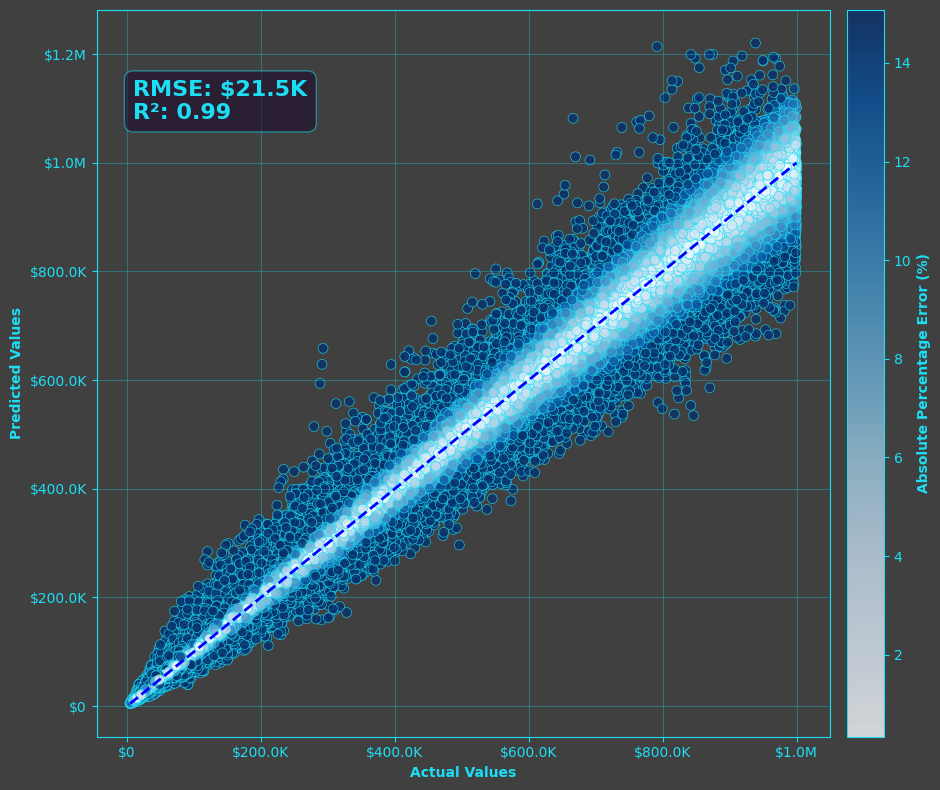

In [42]:
# model metrics
rmse = currency_formatter(np.sqrt(mean_squared_error(actual_values, y_pred)), 1)
r2 = r2_score(actual_values, y_pred)

# percent error
error_pct = np.abs((y_pred - actual_values)/actual_values) * 100

# setting up the plot
plt.figure(figsize=(10, 8))
plt.grid(True, alpha=0.3)
plt.tight_layout()

# want error to be more easily seen by color
error_min = np.percentile(error_pct, 5)  # 5th percentile
error_max = np.percentile(error_pct, 95)  # 95th percentile

# scatter plot
sc = plt.scatter(actual_values, y_pred, 
                c=error_pct, 
                cmap='Blues',
                alpha=0.8,
                s=50,
                vmin=error_min,
                vmax=error_max,
                edgecolors='#1cdff5',
                linewidths=0.5)

# actual = predicted line
plt.plot([actual_values.min(), actual_values.max()], [actual_values.min(), actual_values.max()], 'b--', lw=2)
plt.xlabel('Actual Values', fontweight='bold')
plt.ylabel('Predicted Values', fontweight='bold')

plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))

# color bar
cbar = plt.colorbar(sc, pad=0.02)
cbar.set_label('Absolute Percentage Error (%)', fontweight='bold')
cbar.ax.tick_params(labelsize=10)

# Add text annotation with metrics
metrics_text = f'RMSE: {rmse}\nR²: {r2:.2f}'
plt.annotate(metrics_text, 
             xy=(0.05, 0.85), xycoords='axes fraction',
             bbox=dict(boxstyle="round,pad=0.4", fc="#180128", ec="#1cdff5", alpha=0.50),
             fontsize=16, fontweight='bold')

plt.grid(True, alpha=0.3, color = '#1cdff5')
plt.tight_layout()
plt.show()

## Model Feature Importance

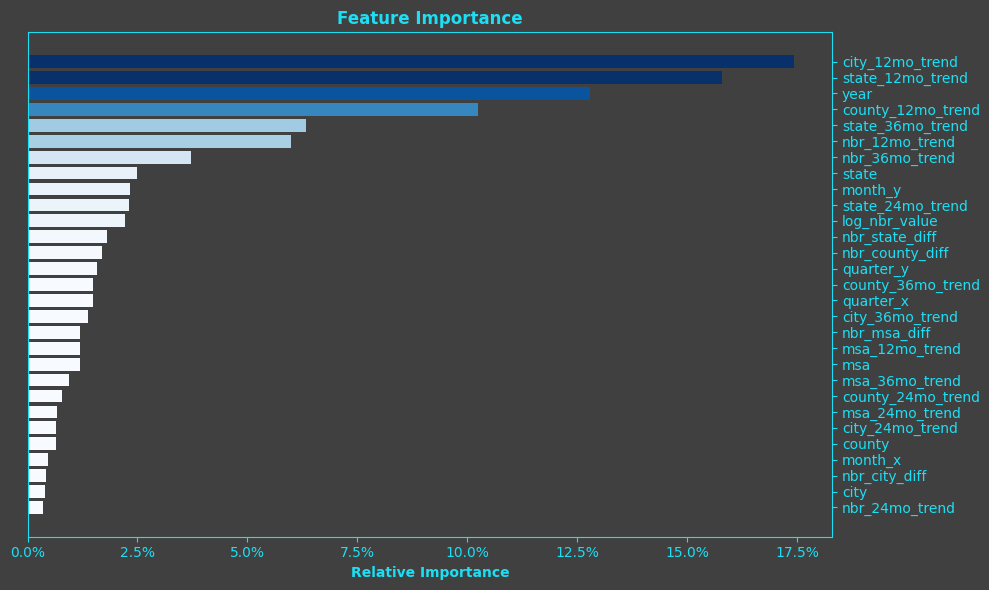

In [43]:
# call model
xgb_model = model.named_steps['model']

# combine names in the correct order matching preprocessor
feature_names = categorical_cols + numeric_cols

# feature importances importances
importances = xgb_model.feature_importances_

# df for plotting
feat_imp_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values(by='importance', ascending=False)

# want good color gradient, i kinda just played with this until it looked better
imp_min = np.percentile(feat_imp_df['importance'], 50)  # 5th percentile
imp_max = np.percentile(feat_imp_df['importance'], 95)  # 95th percentile

# normalize importance
norm_importance = (feat_imp_df['importance'] - imp_min) / (imp_max - imp_min)
colors = cm.Blues(norm_importance)

# plot
plt.figure(figsize=(10, 6))
plt.barh(feat_imp_df['feature'], feat_imp_df['importance'], color=colors)

# styling and elements
plt.xlabel('Relative Importance', fontweight='bold')
plt.title('Feature Importance', fontweight='bold')
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(percent_formatter))
plt.gca().invert_yaxis()
plt.gca().yaxis.tick_right()
plt.tight_layout()
plt.show()

# <b>Jake</b> - Question 5:
### What are the expected profits/return on investments in the top identified markets?

I'm, like, sure I've got a disgustingly overfit model, but we're going to run with it anyway.

In [ ]:
# given what we were seeing in the previous analysis done by my peers, i liked what was going on in tennessee specifically Knoxville.

# at the risk of not having a diverse portfolio, i think the real estate market there
# is relatively insulated from 'act of god' natural disaster events, so i'm not concerned with
# focusing our investment in that state.

# my plan is to look at the best trend from my forecasting model and calculate profits from there

# filtering features to tennessee, scoring, then writing to data
df_tn = df_nbr_features[(df_nbr_features['state'] == 'TN') & (df_nbr_features['date'] >= '2023-03-31')].copy()

df_tn_x = df_tn[features]

# predict residual (difference in log space)
df_tn_preds_diff = full_pipeline.predict(df_tn_x)

# add back the current log value to get predicted log value 2 years out
df_tn_preds_log = df_tn_preds_diff + df_tn['log_nbr_value']

# transform back to dollars
df_tn['predicted_nbr_value'] = np.expm1(df_tn_preds_log)

# selecting only columns i want
df_tn = df_tn[['nbr_id', 'neighborhood', 'city', 'state', 'date', 'nbr_value', 'predicted_nbr_value']]
df_tn['neighborhood_city'] = df_tn['neighborhood'] + ', ' + df_tn['city']

# i want my two years out date
df_tn['date_2y_out'] = df_tn['date'] + pd.DateOffset(years=2)

#########################################################################################################################################
# i'm taking some big liberties here with assumptions, but i'm okay with it since i'm not actually a real-estate mogul with $12M in cash#
#########################################################################################################################################

# let's say we're putting down, i don't know, 20% at first with an added 10% for repairs/updates. let's apply that to just time of purchase
df_tn['upfront_cost'] = np.where(df_tn['date_2y_out'] == '2025-03-31', -0.3*df_tn['nbr_value'], 0)

# a typical monthly mortgage payment is roughly 0.8% of total property value, typical time period for a flip is like a year or two so this is staying basically constant
start_value = df_tn[df_tn['date'] == '2025-03-31'][['nbr_id', 'nbr_value']].set_index('nbr_id')
df_tn['base_nbr_value'] = df_tn['nbr_id'].map(start_value['nbr_value'])
df_tn['mortgage_pymt'] = -0.008 * df_tn['base_nbr_value']
df_tn['ttl_mortgage_paid'] = df_tn.groupby('nbr_id')['mortgage_pymt'].cumsum()
df_tn['ttl_mortgage_left'] = df_tn['base_nbr_value'] + df_tn['ttl_mortgage_paid']

# a typical monthly rent payment is roughly 1.0% of total property value, this is changing month over month instead of just year over year which isn't realistic, but good enough
df_tn['rent_pymt'] = 0.01*df_tn['predicted_nbr_value']

# property tax in Knoxville is roughly 0.40%, but we're only paying that at tax time, so April
df_tn['property_tax'] = np.where(df_tn['date'].dt.month == 4, -0.004*df_tn['predicted_nbr_value'], 0)

# then let's say we're selling March of 2027
df_tn['upfront_cost'] = np.where(df_tn['date_2y_out'] == '2025-03-31', -0.3*df_tn['nbr_value'], 0)
# adding up cogs and income
df_tn['net_income'] = df_tn['upfront_cost'] + df_tn['rent_pymt'] + df_tn['property_tax']
df_tn['ttl_gross_profit'] = df_tn.groupby('nbr_id')['net_income'].cumsum()

# then let's say we're selling March of 2027
df_tn['selling_price'] = np.where(df_tn['date_2y_out'] == '2027-03-31', df_tn['predicted_nbr_value'], 0)
df_tn['final_net_profit'] = np.where(df_tn['date_2y_out'] == '2027-03-31', df_tn['selling_price'] + df_tn['net_income'] - df_tn['ttl_mortgage_left'], 0)
df_tn['min_upfront_cost'] = df_tn.groupby('nbr_id')['upfront_cost'].transform('min')
df_tn['final_roi'] = np.where(df_tn['date_2y_out'] == '2027-03-31', df_tn['final_net_profit']/(-1*df_tn['min_upfront_cost']) - 1, 0)


df_tn[df_tn['date_2y_out'] == '2027-03-31'].to_csv('final_output.csv')

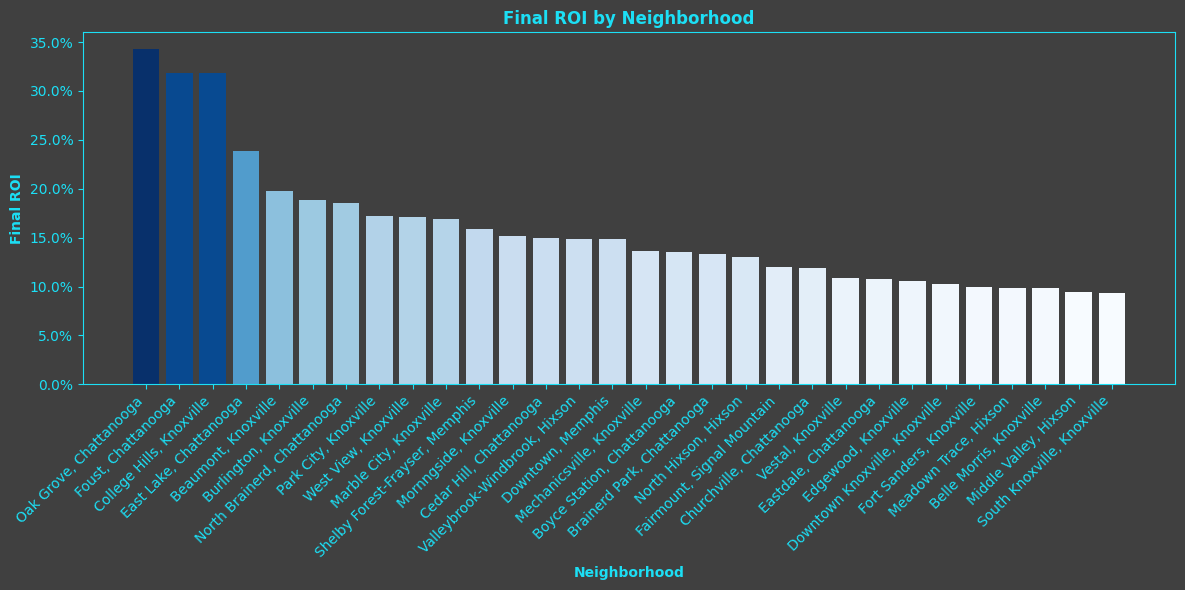

In [ ]:
# top roi neighborhoods
df_plot = df_tn[
    (df_tn['date_2y_out'] == '2027-03-31') &
    (np.isfinite(df_tn['final_roi']))
].sort_values('final_roi', ascending=False).head(30)

norm = plt.Normalize(df_plot['final_roi'].min(), df_plot['final_roi'].max())
colors = cm.Blues(norm(df_plot['final_roi'].values))

# plot
plt.figure(figsize=(12, 6))
plt.bar(df_plot['neighborhood_city'].astype(str), df_plot['final_roi'], color=colors)

# styling and elements
plt.xticks(rotation=90)
plt.xlabel('Neighborhood', fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Final ROI', fontweight='bold')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(percent_formatter))
plt.title('Final ROI by Neighborhood', fontweight='bold')
plt.tight_layout()
plt.show()

## Question 5 Analysis

Looks like there's plenty of neighborhoods in Chattanooga and Knoxville that can yield a great ROI. Oak grove is posting a rate that's nearly 35%. I was a little worried that the model results wouldn't line up with some of the previous analysis done by my peers, but this definitely seems to be a booming real-estate market. I'd say you probably want to diversify your investment so a more realistic ROI in the Knoxville/Chattanooga neighborhoods would be roughly 10-15% after two years and taking into consideration mortgage payments, property tax, and updates to the property.

![oak_grove](oak_grove.png)

Oak Grove looks like a nice place though. I can pick my kid up from elementary school and then take them to get a tattoo at Empress. Talk about convenience!

# <b>Jake</b> - Question 6: 
### What is the expected monthly income on investments in the top identified markets?

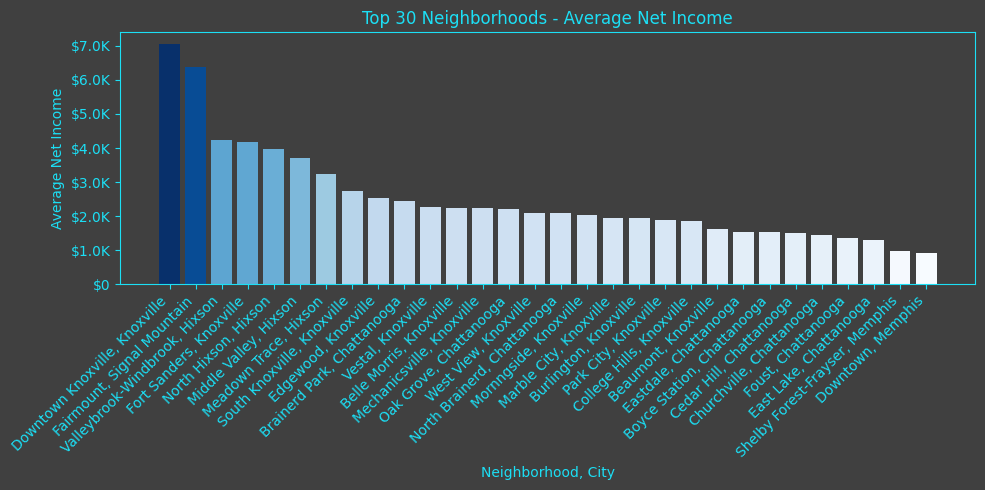

In [95]:
avg_net_income = (
    df_plot.groupby(['nbr_id', 'neighborhood_city'])['net_income']
    .mean()
    .reset_index()
    .sort_values('net_income', ascending=False)
    .head(30)
)

# normalize for colors
norm = plt.Normalize(avg_net_income['net_income'].min(), avg_net_income['net_income'].max())
colors = cm.Blues(norm(avg_net_income['net_income'].values))

# plot
plt.figure(figsize=(10, 5))
plt.bar(avg_net_income['neighborhood_city'], avg_net_income['net_income'], color=colors)

# styling
plt.xticks(rotation=45, ha='right')
plt.xlabel('Neighborhood, City')
plt.ylabel('Average Net Income')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(currency_formatter))
plt.title('Top 30 Neighborhoods - Average Net Income')
plt.tight_layout()
plt.show()

## Question 6 Analysis

Probably makes sense that the highest net incomes would come from a downtown area considering the property values are probably going to be the highest. Some of our top ROI neighborhoods are middle of the pack here, but we're going for ROI rather than raw net income here. Looks like we're roughly in the range of two to three thousand dollars a month.

All in all, there's plenty of neighborhoods in Knoxville and Chattanooga where buying up real-estate can yield a good 10-15% ROI and a couple thousand bucks in monthly net income. If you're in the market and have the capital, this is probably some of the best opportunity in the country!